In [1]:
from collections import defaultdict
from pathlib import Path
import pandas as pd
import numpy as np

In [7]:
absolute_data_path = Path.cwd()

seasons = ["2016-17", "2017-18", "2018-19", "2019-20", "2020-21","2021-22", "2022-23",
            "2023-24", "2024-25", "2025-26", "2026-27"]

sdf = {}

for season in seasons:
    selected = pd.read_csv(absolute_data_path/f"Fantasy-Premier-League-master/data/{season}/gws/merged_gw.csv",
                           encoding="latin-1")
    selected["season"] = season
    sdf[season] = selected

In [6]:
with pd.option_context('display.max_columns', None, 'display.width', 1000):
    print(sdf['2025-26'][5000:5007])

                        name position           team   xP  assists  bonus  bps  clean_sheets  creativity  element  expected_assists  expected_goal_involvements  expected_goals  expected_goals_conceded  fixture  goals_conceded  goals_scored  ict_index  influence          kickoff_time  minutes  modified  opponent_team  own_goals  penalties_missed  penalties_saved  red_cards  round  saves  selected  starts  team_a_score  team_h_score  threat  total_points  transfers_balance  transfers_in  transfers_out  value  was_home  yellow_cards  clearances_blocks_interceptions  defensive_contribution  recoveries  tackles  GW   season
5000         Adrien Truffert      DEF    Bournemouth  0.0        1      0   24             0        20.2       74              0.04                        0.07            0.03                     0.88       63               1             0        5.7       32.8  2025-10-03T19:00:00Z       90     False             10          0                 0                0          

In [8]:
df1 = sdf["2025-26"]
df2 = sdf["2026-27"]
# 2016-27 through 2018-19 have the same columns
# 2019-20 drops columns
# 2020-21 adds columns
# pre 2019-20 has not positon/element_type column
# 2020-21 is the first year with player team 
# from 2020-21:
#   2022-23 adds columns, 
#   2024-25 adds mng columns,
#   2025-26 adds defcon

only_in_df1 = set(df1.columns) - set(df2.columns)
only_in_df2 = set(df2.columns) - set(df1.columns)
in_both = set(df2.columns) & set(df1.columns)

dict_compare = {"Columns only in df1": list(only_in_df1),
                "Columns in both": list(in_both),
                "Columns only in df2": list(only_in_df2)}

df_compare = pd.DataFrame({k: pd.Series(v) for k, v in dict_compare.items()})

print(df_compare.to_string())


   Columns only in df1                  Columns in both Columns only in df2
0                  NaN                           threat                 NaN
1                  NaN                        red_cards                 NaN
2                  NaN                        influence                 NaN
3                  NaN                          element                 NaN
4                  NaN                     yellow_cards                 NaN
5                  NaN                            bonus                 NaN
6                  NaN                     clean_sheets                 NaN
7                  NaN                 expected_assists                 NaN
8                  NaN                             name                 NaN
9                  NaN                     transfers_in                 NaN
10                 NaN                 penalties_missed                 NaN
11                 NaN                          assists                 NaN
12          

-cut all before 2020-21
-need to normalise pre and post defcon, from 2025-26, can be done using other stats fairly easily
-2022-23 introduces: xGC, xA, starts, xG, xGI, these can be left NaN for tree modles, need to be filled with proxies or removed for non tree modles
-need to make an xMinutes proxy as data isnt available to make a proper xMins calculation for past years

In [138]:
for season, df in sdf.items():
    columns_with_nan = df.columns[df.isna().any()]
    print(columns_with_nan)

Index([], dtype='str')
Index([], dtype='str')
Index([], dtype='str')
Index(['team_a_score', 'team_h_score'], dtype='str')
Index([], dtype='str')
Index([], dtype='str')
Index([], dtype='str')
Index([], dtype='str')
Index(['mng_clean_sheets', 'mng_draw', 'mng_goals_scored', 'mng_loss',
       'mng_underdog_draw', 'mng_underdog_win', 'mng_win'],
      dtype='str')
Index([], dtype='str')


In [149]:
mng_columns = ["mng_clean_sheets", "mng_draw", "mng_goals_scored", "mng_loss",
                "mng_underdog_draw", "mng_underdog_win", "mng_win"]

#sdf["2024-25"].drop(columns=mng_columns, inplace=True)
sdf["2020-21"].info()

<class 'pandas.DataFrame'>
RangeIndex: 24365 entries, 0 to 24364
Data columns (total 37 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               24365 non-null  str    
 1   position           24365 non-null  str    
 2   team               24365 non-null  str    
 3   xP                 24365 non-null  float64
 4   assists            24365 non-null  int64  
 5   bonus              24365 non-null  int64  
 6   bps                24365 non-null  int64  
 7   clean_sheets       24365 non-null  int64  
 8   creativity         24365 non-null  float64
 9   element            24365 non-null  int64  
 10  fixture            24365 non-null  int64  
 11  goals_conceded     24365 non-null  int64  
 12  goals_scored       24365 non-null  int64  
 13  ict_index          24365 non-null  float64
 14  influence          24365 non-null  float64
 15  kickoff_time       24365 non-null  str    
 16  minutes            24365 non-null

In [6]:
# these 2 cells are to make sure all dfs were merging have the same columns before concatinating
pre_21_missing = ["expected_goals_conceded", "expected_assists", "clean_sheets", "starts",
                   "influence", "expected_goals", "expected_goal_involvements"]

for column in pre_21_missing:
    sdf["2021-22"][column] = np.nan
    sdf["2020-21"][column] = np.nan

In [7]:
defcon_columns = ["recoveries", "defensive_contribution", "clearances_blocks_interceptions", "tackles"]
pre_defcon_years = ["2020-21", "2021-22", "2022-23", "2023-24", "2024-25"]

for year in pre_defcon_years:
    for column in defcon_columns:
        sdf[year][column] = np.nan

In [8]:
# removing years stated earlier
sdict = sdf
years_to_remove = ["2016-17", "2017-18", "2018-19", "2019-20"]

for year in years_to_remove:
    del(sdict[year])

sdict.keys()

dict_keys(['2020-21', '2021-22', '2022-23', '2023-24', '2024-25', '2025-26'])

In [9]:
for season, df in sdict.items():
    if "modified" in df.columns:
        sdict[season] = df.drop(columns="modified")
        print(f"removed modified from {season}")

removed modified from 2024-25
removed modified from 2025-26


In [156]:
df = sdf["2025-26"]

columns_to_remove = [
        "net_transfers",
        "modified",
        "xP",
        "expected_goals",
        "expected_assists",
        "expected_goal_involvements",
        "expected_goals_conceded",
        "round",
        "mng_clean_sheets",
        "mng_draw", 
        "mng_goals_scored", 
        "mng_loss",
        "mng_underdog_draw", 
        "mng_underdog_win", 
        "mng_win",
        "kickoff_time",
        "round",
        "name",
        'ict_index',
        'defensive_contribution'
        ]
    
df = df.drop(columns=columns_to_remove, errors="ignore")


master_columns = set(df.columns)

#same_columns = all(set(df.columns)==master_columns for df in sdict.values())

print(len(master_columns))
for _ in master_columns:
    print(_)

36
influence
tackles
fixture
recoveries
goals_scored
penalties_missed
clearances_blocks_interceptions
element
creativity
position
was_home
own_goals
red_cards
saves
total_points
bps
transfers_balance
starts
penalties_saved
yellow_cards
clean_sheets
team
selected
transfers_out
team_a_score
season
threat
value
assists
team_h_score
minutes
GW
transfers_in
opponent_team
goals_conceded
bonus


----before merging----
-make sure team and player ids are constant across seasons
-rolling features? (inc xMinutes)
-make sure columns across seasons are in same type
-sort each season by player then fixture

In [110]:
sdict["2020-21"].info()

<class 'pandas.DataFrame'>
RangeIndex: 24365 entries, 0 to 24364
Data columns (total 47 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   name                             24365 non-null  str    
 1   position                         24365 non-null  str    
 2   team                             0 non-null      str    
 3   xP                               24365 non-null  float64
 4   assists                          24365 non-null  float64
 5   bonus                            24365 non-null  float64
 6   bps                              24365 non-null  float64
 7   clean_sheets                     0 non-null      float64
 8   creativity                       24365 non-null  float64
 9   element                          24365 non-null  float64
 10  fixture                          24365 non-null  float64
 11  goals_conceded                   24365 non-null  float64
 12  goals_scored                 

In [12]:
# alredy have xA and xG so xGI is redundant
for season in sdict:
    sdict[season].drop(columns="expected_goal_involvements")

In [13]:
# trans in and out are unneeded as we have net transfer
for season in sdict:
    sdict[season].drop(columns=["transfers_in", "transfers_out"])

Use ridge regression to find influence based on ict, threat, creativity
check if round and gw are the same after combining and remove one

In [148]:
type_records = []
for season, df in sdf.items():
    for col_name, dtype in df.dtypes.items():
        type_records.append({
            'Season': season, 
            'Column': col_name, 
            'DataType': str(dtype)
        })

# Convert records to a DataFrame for processing
df_types = pd.DataFrame(type_records)

# 2. Filter down to columns that have MORE THAN ONE unique data type
mismatched_columns = df_types.groupby('Column').filter(lambda group: group['DataType'].nunique() > 1)

# 3. Pivot the results into a scannable comparison chart
if not mismatched_columns.empty:
    comparison_table = mismatched_columns.pivot(index='Column', columns='Season', values='DataType')
    print("found dtype mismatch\n")
    print(comparison_table)
else:
    print("dtypes match")

found dtype mismatch

Season       2016-17 2017-18  2018-19  2019-20  2020-21  2021-22  2022-23  \
Column                                                                      
team_a_score   int64   int64    int64  float64    int64    int64    int64   
team_h_score   int64   int64    int64  float64    int64    int64    int64   
threat         int64   int64  float64  float64  float64  float64  float64   

Season        2023-24  2024-25  2025-26  
Column                                   
team_a_score    int64    int64    int64  
team_h_score    int64    int64    int64  
threat        float64  float64  float64  


In [15]:
catagoracol_cols = ["name", "position", "team", "total_points", "season"]

for season, df in sdict.items():
    for col in df.columns:
        if col not in catagoracol_cols:
            df[col] = pd.to_numeric(df[col], errors='coerce').astype('float64')

sdict["2025-26"].info()

<class 'pandas.DataFrame'>
RangeIndex: 29757 entries, 0 to 29756
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   name                             29757 non-null  str    
 1   position                         29757 non-null  str    
 2   team                             29757 non-null  str    
 3   xP                               29757 non-null  float64
 4   assists                          29757 non-null  float64
 5   bonus                            29757 non-null  float64
 6   bps                              29757 non-null  float64
 7   clean_sheets                     29757 non-null  float64
 8   creativity                       29757 non-null  float64
 9   element                          29757 non-null  float64
 10  expected_assists                 29757 non-null  float64
 11  expected_goal_involvements       29757 non-null  float64
 12  expected_goals               

In [16]:
with pd.option_context('display.max_columns', None, 'display.width', 1000):
    print(sdict["2025-26"].head())

# element should be a string
# separate mettadata columns before converting to floats 

                             name position         team   xP  assists  bonus   bps  clean_sheets  creativity  element  expected_assists  expected_goal_involvements  expected_goals  expected_goals_conceded  fixture  goals_conceded  goals_scored  ict_index  influence  kickoff_time  minutes  opponent_team  own_goals  penalties_missed  penalties_saved  red_cards  round  saves  selected  starts  team_a_score  team_h_score  threat  total_points  transfers_balance  transfers_in  transfers_out  value  was_home  yellow_cards  clearances_blocks_interceptions  defensive_contribution  recoveries  tackles   GW   season
0                Reinildo Mandava      DEF   Sunderland  0.5      0.0    0.0  27.0           1.0         2.5    541.0              0.00                        0.00             0.0                     0.56      5.0             0.0           0.0        1.6       13.6           NaN     90.0           19.0        0.0               0.0              0.0        0.0    1.0    0.0  677026.0  

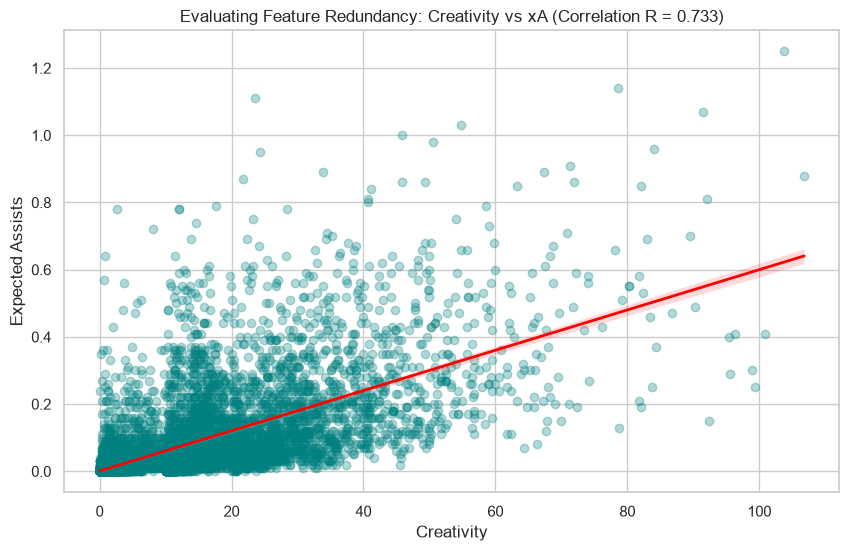

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

df = sdict["2025-26"]

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df, 
    x='creativity', 
    y='expected_assists',
    scatter_kws={'alpha':0.3, 'color':'teal'},
    line_kws={'color':'red', 'linewidth':2}
)

r_val = df['creativity'].corr(df['expected_assists']).round(3)

plt.title(f'Evaluating Feature Redundancy: Creativity vs xA (Correlation R = {r_val})')
plt.xlabel('Creativity')
plt.ylabel('Expected Assists')
plt.show()

In [18]:
def get_correlation_plot(feature_x, feature_y):
    sns.regplot(
        data=df, 
        x=feature_x, 
        y=feature_y,
        scatter_kws={'alpha':0.3, 'color':'teal'}, 
        line_kws={'color':'red', 'linewidth':2}
    )

    r_val = df[feature_x].corr(df[feature_y]).round(3)

    plt.title(f'Evaluating Feature Redundancy: {feature_x} vs {feature_y} (Correlation R = {r_val})')
    plt.xlabel(feature_x)
    plt.ylabel(feature_y)
    plt.show()

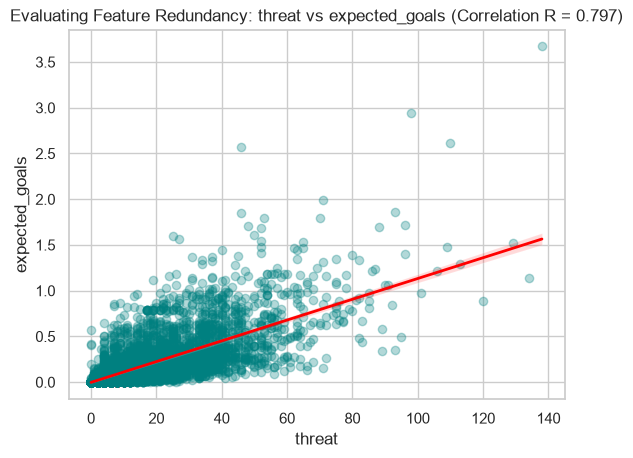

In [19]:
get_correlation_plot("threat","expected_goals")

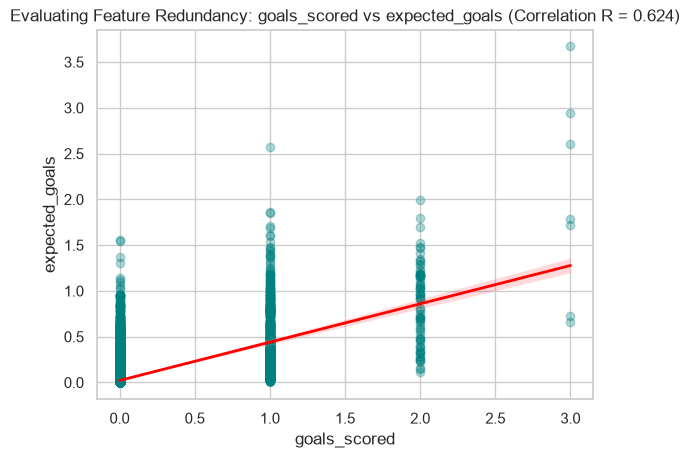

In [20]:
get_correlation_plot("goals_scored","expected_goals")

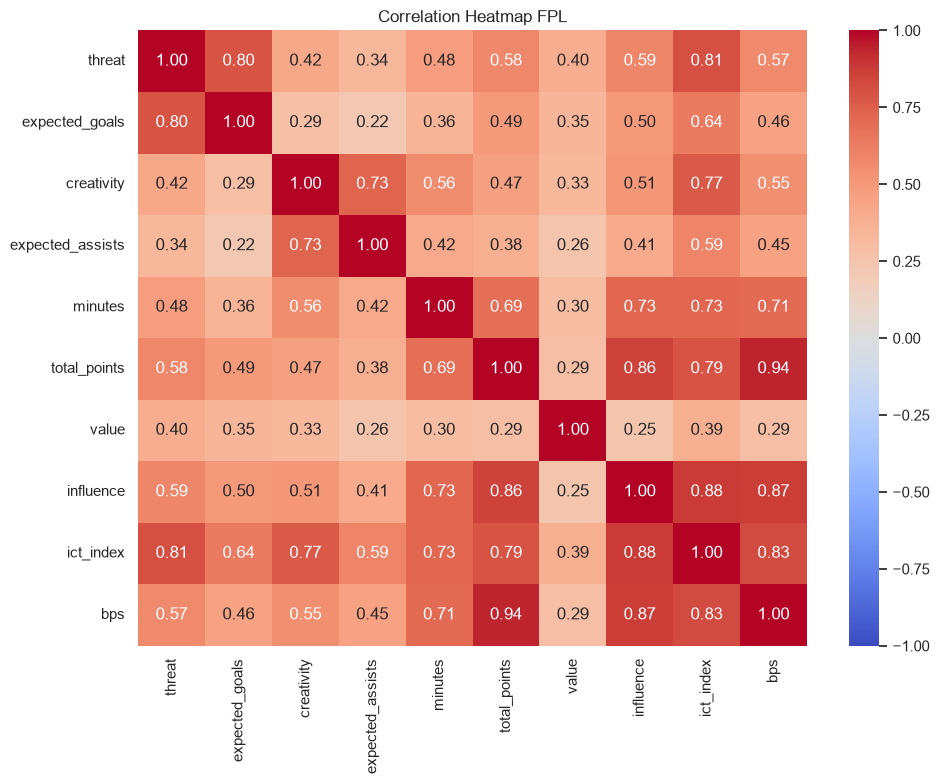

In [21]:
df = sdict["2025-26"]

features_to_check = [
    "threat", "expected_goals", 
    "creativity", "expected_assists", 
    "minutes", "total_points", "value",
    "influence", "ict_index", "bps"
]

correlation_matrix = df[features_to_check].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    data=correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Heatmap FPL")
plt.tight_layout()
plt.show()

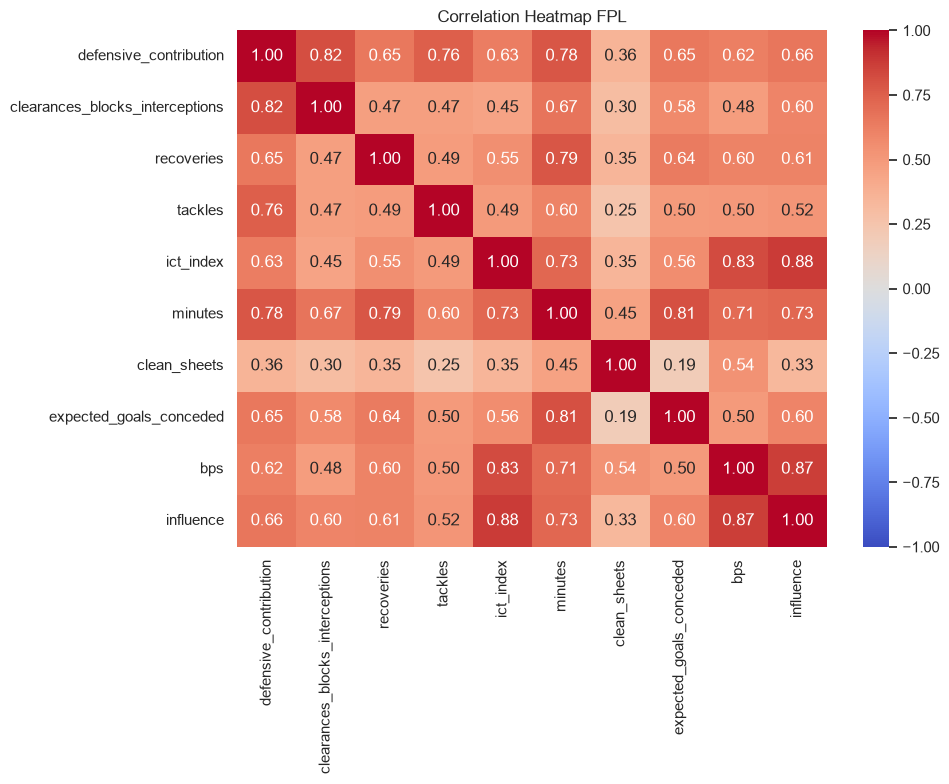

In [65]:
features_to_check = [
    "defensive_contribution", "clearances_blocks_interceptions",
    "recoveries", "tackles", "ict_index", "minutes", 
    "clean_sheets", "expected_goals_conceded", "bps", "influence" 
]

correlation_matrix = df[features_to_check].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    data=correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Heatmap FPL")
plt.tight_layout()
plt.show()

rolling stats
make sure ids constant 
xMins and make sure all stats are only based off previous GWs

In [109]:
sdict["2021-22"].info()

<class 'pandas.DataFrame'>
RangeIndex: 25447 entries, 0 to 25446
Data columns (total 47 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   name                             25447 non-null  str    
 1   position                         25447 non-null  str    
 2   team                             0 non-null      str    
 3   xP                               25447 non-null  float64
 4   assists                          25447 non-null  float64
 5   bonus                            25447 non-null  float64
 6   bps                              25447 non-null  float64
 7   clean_sheets                     0 non-null      float64
 8   creativity                       25447 non-null  float64
 9   element                          25447 non-null  float64
 10  fixture                          25447 non-null  float64
 11  goals_conceded                   25447 non-null  float64
 12  goals_scored                 

In [24]:
#finding influence from ict and creativity and threat

from sklearn.linear_model import Ridge

# train on 
df_complete = sdict["2025-26"].copy()

# Filter out players who didn't play to avoid mathematical zero noise
df_modern_complete = df_complete[df_complete["minutes"] > 0]

X_train = df_modern_complete[['ict_index', 'threat', 'creativity']]
y_train = df_modern_complete['influence']

# Train a Ridge model to reverse-engineer the exact FPL component weights
formula_solver = Ridge()
formula_solver.fit(X_train, y_train)


# --- STEP 2: BACKFILL THE MISSING YEARS ---
# Run this inside your loop for any early season missing the 'influence' column
for season_name, df in sdict.items():
    if 'influence' not in df.columns or df['influence'].isnull().all():
        
        # check all floats
        for col in ['ict_index', 'threat', 'creativity', 'minutes']:
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0.0)
            
        # Predict values only for rows where the player actually played minutes
        active_mask = df['minutes'] > 0
        if active_mask.any():
            X_missing = df.loc[active_mask, ['ict_index', 'threat', 'creativity']]
            df.loc[active_mask, 'influence'] = formula_solver.predict(X_missing)
            
        # benched players get no minutes
        df.loc[df['minutes'] == 0, 'influence'] = 0.0

        
""" # Now that influence is restored, build your safe lagging features
df = df.sort_values(by=['element', 'GW'])

# Calculate defensive work rate per minute
df['def_work_rate'] = df['influence'] / (df['minutes'] + 1.0)

# Generate the non-leaking trailing 3-match rolling average proxy for your model
df['proxy_defcon_intent'] = df.groupby('element')['def_work_rate'].transform(
    lambda x: x.rolling(window=3, min_periods=1).mean().shift(1)
).fillna(0.0)

# Save the repaired dataframe back to your storage dictionary
dfs[season_name] = df"""

" # Now that influence is restored, build your safe lagging features\ndf = df.sort_values(by=['element', 'GW'])\n\n# Calculate defensive work rate per minute\ndf['def_work_rate'] = df['influence'] / (df['minutes'] + 1.0)\n\n# Generate the non-leaking trailing 3-match rolling average proxy for your model\ndf['proxy_defcon_intent'] = df.groupby('element')['def_work_rate'].transform(\n    lambda x: x.rolling(window=3, min_periods=1).mean().shift(1)\n).fillna(0.0)\n\n# Save the repaired dataframe back to your storage dictionary\ndfs[season_name] = df"

for tree based models save a copy first as they handel NaN values fine 

In [25]:
with pd.option_context('display.max_columns', None, 'display.width', 1000):
    print(sdict["2020-21"].head())

                  name position           team   xP  assists  bonus   bps  clean_sheets  creativity  element  fixture  goals_conceded  goals_scored  ict_index  influence  kickoff_time  minutes  opponent_team  own_goals  penalties_missed  penalties_saved  red_cards  round  saves  selected  team_a_score  team_h_score  threat  total_points  transfers_balance  transfers_in  transfers_out  value  was_home  yellow_cards   GW   season  expected_goals_conceded  expected_assists  starts  expected_goals  expected_goal_involvements  recoveries  defensive_contribution  clearances_blocks_interceptions  tackles
0       Aaron Connolly      FWD       Brighton  0.5      0.0    0.0  -3.0           NaN         0.3     78.0      7.0             2.0           0.0        3.4   1.975563           NaN     45.0            5.0        0.0               0.0              0.0        0.0    1.0    0.0   32205.0           3.0           1.0    32.0             1                0.0           0.0            0.0   55.0  

In [26]:
for season, df in sdict.items():
    r_val = df['ict_index'].corr(df['influence']).round(3)
    print(f"{season} {r_val}")

2020-21 0.847
2021-22 0.852
2022-23 0.857
2023-24 0.874
2024-25 0.869
2025-26 0.877


In [31]:
for season, df in sdict.items():
    df = df.sort_values(by=['element', 'GW'])

sdict["2020-21"].info()

<class 'pandas.DataFrame'>
RangeIndex: 24365 entries, 0 to 24364
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   name                             24365 non-null  str    
 1   position                         24365 non-null  str    
 2   team                             24365 non-null  str    
 3   xP                               24365 non-null  float64
 4   assists                          24365 non-null  float64
 5   bonus                            24365 non-null  float64
 6   bps                              24365 non-null  float64
 7   clean_sheets                     0 non-null      float64
 8   creativity                       24365 non-null  float64
 9   element                          24365 non-null  float64
 10  fixture                          24365 non-null  float64
 11  goals_conceded                   24365 non-null  float64
 12  goals_scored                 

In [ ]:
def normalise_season_teams(season_name):
    df = sdict[season_name]

    teams_url = f"Fantasy-Premier-League-master/data/{season_name}/teams.csv"
    df_teams = pd.read_csv(teams_url)
    
    s_teams = df_teams.set_index("name")["code"]
    
    df["team"] = df["team"].map(s_teams)
    df["opponent_team"] = df["opponent_team"].map(s_teams)
    
    return df


In [131]:
temp_data = pd.read_csv(absolute_data_path/f"Fantasy-Premier-League-master/data/2020-21/gws/merged_gw.csv",
                           encoding="latin-1")

teams_url = f"Fantasy-Premier-League-master/data/2020-21/teams.csv"
df_teams = pd.read_csv(teams_url)

s_teams = df_teams.set_index("name")["code"]

temp_data["team"] = temp_data["team"].map(s_teams)
temp_data["opponent_team"] = temp_data["opponent_team"].map(s_teams)

temp_data["tackles"].value_counts()

KeyError: 'tackles'

In [114]:
sdict["2024-25"]["team"]

0        NaN
1        NaN
2        NaN
3        NaN
4        NaN
        ... 
27600    NaN
27601    NaN
27602    NaN
27603    NaN
27604    NaN
Name: team, Length: 27605, dtype: str

In [ ]:
for season in sdict:
    normalise_season_teams(season_name=season)

In [41]:
players_temp = pd.read_csv(absolute_data_path/f"Fantasy-Premier-League-master\data/2019-20\players_raw.csv",
                           encoding="latin-1")

<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
C:\Users\Thoma_m\AppData\Local\Temp\ipykernel_6572\3791214236.py:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  players_temp = pd.read_csv(absolute_data_path/f"Fantasy-Premier-League-master\data/2019-20\players_raw.csv",


In [53]:
players_temp.groupby("code").head()

,assists,bonus,bps,chance_of_playing_next_round,chance_of_playing_this_round,clean_sheets,code,cost_change_event,cost_change_event_fall,cost_change_start,...,threat_rank_type,total_points,transfers_in,transfers_in_event,transfers_out,transfers_out_event,value_form,value_season,web_name,yellow_cards
0,2,2,242,0.0,0.0,4,69140,0,0,-4,...,58,43,25007,0,47630,0,0.3,8.4,Mustafi,2
1,0,4,204,100.0,100.0,4,98745,0,0,-3,...,81,44,206616,0,159819,0,0.3,8.5,BellerÃ­n,2
2,2,1,331,100.0,100.0,4,111457,0,0,-3,...,98,55,65194,0,134275,0,0.5,10.6,Kolasinac,4
3,2,3,244,100.0,100.0,3,154043,0,0,-5,...,119,41,610816,0,653555,0,0.1,9.1,Maitland-Niles,4
4,0,5,305,100.0,100.0,4,39476,0,0,-2,...,76,57,182201,0,231413,0,0.0,11.9,Sokratis,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
661,0,0,0,NaN,NaN,0,179456,0,0,0,...,189,0,12504,0,7078,0,0.0,0.0,Buur,0
662,0,0,0,0.0,0.0,0,232351,0,0,-1,...,181,0,21912,0,11421,0,0.0,0.0,Giles,0
663,0,0,4,NaN,NaN,0,428610,0,0,0,...,246,1,1913,0,1146,0,0.0,0.2,Jordao,0
664,1,2,74,NaN,NaN,3,200600,0,0,-6,...,124,25,8281,0,3461,0,0.6,5.1,Podence,0


In [49]:
def normalise_season_players(season_name):
    df = sdict[season_name]

    players_url = f"Fantasy-Premier-League-master\data/{season_name}\players_raw.csv"
                          
    df_players = pd.read_csv(players_url, encoding="latin-1")
    
    s_players = df_players.set_index("id")["code"]
    
    df["code"] = df["element"].map(s_players)
    
    return df


<>:4: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:4: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:4: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:4: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\Thoma_m\AppData\Local\Temp\ipykernel_6572\3947619768.py:4: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  players_url = f"Fantasy-Premier-League-master\data/{season_name}\players_raw.csv"
C:\Users\Thoma_m\AppData\Local\Temp\ipykernel_6572\3947619768.py:4: SyntaxWarning: "\p" i

In [ ]:
for season in sdict:
    normalise_season_players(season_name=season)

sdict["2025-26"]["code"].value_counts()

<class 'pandas.Series'>
RangeIndex: 29757 entries, 0 to 29756
Series name: code
Non-Null Count  Dtype
--------------  -----
29757 non-null  int64
dtypes: int64(1)
memory usage: 232.6 KB


In [ ]:
print(sdict["2025-26"][["code", "name"]])
print(sdict["2023-24"][["code", "name"]])

         code                            name
0      434399                Reinildo Mandava
1      461421                    Lewis Dobbin
2      158499                   Ryan Christie
3      492831                    Zeki Amdouni
4      224024  Lucas Tolentino Coelho de Lima
...       ...                             ...
29752  441264                   Brian Brobbey
29753  485337                  Evann Guessand
29754  593174                       Kaye Furo
29755  467169               Antony dos Santos
29756  461446                   Tyler Onyango

[29757 rows x 2 columns]
         code                     name
0      471848              Femi Seriki
1      532529         Jack Hinshelwood
2      209243             Jadon Sancho
3      443211   Rhys Norrington-Davies
4      204580            Vitaly Janelt
...       ...                      ...
29720   58621              Kyle Walker
29721  242453              Jacob Brown
29722   40836           Vicente Guaita
29723  437476  Braian Ojeda Rodr

In [56]:
for season, df in sdict.items():
    df= df.sort_values(['code', 'season', 'GW'])

In [115]:
window_size = 3

df = sdict["2025-26"]

df['roll_3_points'] = (
    df.groupby(['season', 'code'])['total_points']
    .transform(lambda x: x.shift(1).rolling(window=window_size, min_periods=1).mean())
)
"""
with pd.option_context('display.max_columns', None, 'display.width', 1000):
    print(df.head())"""

sdict["2025-26"]["was_home"].value_counts()

was_home
1.0    14885
0.0    14872
Name: count, dtype: int64

In [116]:
master_columns

{'GW',
 'assists',
 'bonus',
 'bps',
 'clean_sheets',
 'clearances_blocks_interceptions',
 'creativity',
 'defensive_contribution',
 'element',
 'expected_assists',
 'expected_goal_involvements',
 'expected_goals',
 'expected_goals_conceded',
 'fixture',
 'goals_conceded',
 'goals_scored',
 'ict_index',
 'influence',
 'kickoff_time',
 'minutes',
 'name',
 'opponent_team',
 'own_goals',
 'penalties_missed',
 'penalties_saved',
 'position',
 'recoveries',
 'red_cards',
 'round',
 'saves',
 'season',
 'selected',
 'starts',
 'tackles',
 'team',
 'team_a_score',
 'team_h_score',
 'threat',
 'total_points',
 'transfers_balance',
 'transfers_in',
 'transfers_out',
 'value',
 'was_home',
 'xP',
 'yellow_cards'}

In [120]:
for season, df in sdict.items():
    print(df["clean_sheets"].value_counts())


Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)
clean_sheets
0.0    24194
1.0     2311
Name: count, dtype: int64
clean_sheets
0.0    27822
1.0     1903
Name: count, dtype: int64
clean_sheets
0.0    25525
1.0     2080
Name: count, dtype: int64
clean_sheets
0.0    27508
1.0     2249
Name: count, dtype: int64


In [78]:
def standardize_gameweeks(df):
    """Enforces a clean integer timeline and removes redundant tracking columns."""
    # If 'GW' exists and contains text like 'GW1', strip the letters out
    if 'GW' in df.columns and df['GW'].dtype == 'object' or "float":
        df['GW'] = df['GW'].astype(str).str.extract(r'(\d+)').astype(int)
        
    # Standardise: Make sure 'round' is also a clean integer
    if 'round' in df.columns:
        df['round'] = df['round'].astype(int)
        
    # Check if they are identical in this dataframe. If they are, drop 'round' to prevent bloat.
    if 'GW' in df.columns and 'round' in df.columns:
        if df['GW'].equals(df['round']):
            df = df.drop(columns=['round'])
            
    return df


In [91]:
standardize_gameweeks(sdict["2022-23"])
sdict["2023-24"]["GW"].value_counts() - sdict["2023-24"]["round"].value_counts()

GW
37    0
34    0
25    0
35    0
28    0
38    0
36    0
33    0
32    0
31    0
30    0
27    0
24    0
23    0
7     0
22    0
21    0
20    0
19    0
16    0
15    0
14    0
13    0
12    0
11    0
10    0
9     0
8     0
6     0
5     0
4     0
18    0
17    0
3     0
1     0
26    0
2     0
29    0
Name: count, dtype: int64

In [ ]:
for season, df in sdf.items():
    if 'GW' in df.columns and df['GW'].dtype == 'object':
        df['GW'] = df['GW'].astype(str).str.extract(r'(\d+)').astype(int)
    elif 'GW' in df.columns:
        df['GW'] = df['GW'].astype(int)

In [ ]:
df = sdf["2025-26"]

features_to_check = [
    "defensive_contribution", "clearances_blocks_interceptions",
    "recoveries", "tackles", "ict_index", "minutes", 
    "clean_sheets", "expected_goals_conceded", "bps", "influence" 
]

correlation_matrix = df[features_to_check].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    data=correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Heatmap FPL")
plt.tight_layout()
plt.show()